# Big Data Architecture

Un espacio para **jugar** con todo lo del proyecto: HDFS, Spark SQL, planes de ejecución, Kafka, un stream en vivo y
los modelos de MLlib. Las lecciones (`lessons/`) muestran cada tema en orden; aquí puedes cambiar cualquier cosa y
volver a ejecutar.

**Cómo usarlo**

1. Ejecuta las celdas de **Configuración** (secciones 0 y 1) una vez.
2. Después salta a la sección que quieras. Las celdas marcadas con **Juega aquí** están hechas para que las cambies.
3. Nada de lo que hagas aquí rompe el proyecto: lo que escribes va a `/sandbox` en HDFS y al tema `sandbox-events`
   de Kafka. Si alteras el data lake, `python lessons/00_seed.py` y `04_spark_sql.py` lo dejan como al principio.

> Requisito: haber ejecutado las lecciones 00 y 04 (data lake) y la 08 (modelo) al menos una vez.

| # | Sección | Qué puedes probar |
| --- | --- | --- |
| 0 | Configuración | SparkSession en YARN, ejecutores y Spark UI |
| 1 | Herramientas | Funciones `sql`, `hdfs`, `plan`, `bloques`, `particiones`, `topico` |
| 2 | Explorar el data lake | Zonas bronze, silver y gold con SQL |
| 3 | HDFS | Tamaño de bloque, replicación y dónde vive cada bloque |
| 4 | Análisis y gráficos | Curvas de carga, consumo contra temperatura, eventos de la red |
| 5 | Planes y rendimiento | `explain`, poda de particiones, joins, shuffle |
| 6 | Kafka | Tu propio tema: producir, consumir y medir el lag |
| 7 | Streaming en vivo | Una consulta de streaming sobre el simulador, consultada mientras corre |
| 8 | MLlib | El modelo de consumo: real contra predicho y escenarios "¿qué pasa si?" |
| 9 | Tu propio experimento | Tus datos en `/sandbox` |

## 0. Configuración

La SparkSession usa YARN (`SPARK_MASTER=yarn` en `.envs/lab.env`) y la configuración de `.docker/spark/`. El driver
es este notebook; los ejecutores corren en worker1 y worker2. El notebook usa las mismas funciones que las lecciones
(`src/lab/`). Para no ocupar el clúster cuando termines, ejecuta `spark.stop()` (última celda).

In [1]:
import json
import threading
import time
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F

from lab import dataset
from lab.config import BRONZE, GOLD, KAFKA_BOOTSTRAP_SERVERS, MODELS, READINGS_TOPIC, SILVER
from lab.hdfs import datanodes, yarn_nodes
from lab.hdfs import hdfs as hdfs_cli
from lab.kafka import admin, consumer, describe_topic, producer
from lab.simulator import Replay
from lab.spark import describe, rest, session

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

spark = session("sandbox")
describe(spark)
for name in ("readings", "meters", "weather", "inspections"):
    spark.read.parquet(f"{SILVER}/{name}").createOrReplaceTempView(name)
for name in ("daily_meter", "feeder_hourly"):
    spark.read.parquet(f"{GOLD}/{name}").createOrReplaceTempView(name)
print("vistas:", [t.name for t in spark.catalog.listTables()])
pd.DataFrame(rest(spark, "executors"))[["id", "hostPort", "totalCores", "maxMemory"]]

12:12:07 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark 4.2.0 · master=yarn · app=application_1791651238405_0010 · ejecutores=1 · paralelismo=2
Spark UI: http://localhost:8088/proxy/application_1791651238405_0010/
vistas: ['daily_meter', 'feeder_hourly', 'inspections', 'meters', 'readings', 'weather']


,id,hostPort,totalCores,maxMemory
0,driver,lab:44377,0,455501414
1,2,worker2:38103,2,213909504
2,1,worker2:42699,2,213909504


## 1. Herramientas

Funciones cortas para no repetir código. Están aquí, a la vista, para que las leas y las cambies.

| Función | Qué hace |
| --- | --- |
| `sql(consulta, n)` | Ejecuta Spark SQL y devuelve las primeras `n` filas como DataFrame de pandas |
| `hdfs(*args)` | La CLI de HDFS: `hdfs("dfs", "-ls", "/datalake")` |
| `plan(df_o_sql)` | Imprime el plan físico (lo que Spark va a ejecutar) |
| `bloques(ruta)` | Los bloques de un archivo de HDFS y los DataNodes que guardan cada réplica |
| `particiones(df)` | Cuántas filas tiene cada partición de un DataFrame |
| `topico(nombre)` | Particiones, líder, réplicas e ISR de un tema de Kafka |

In [2]:
def sql(consulta, n=1000):
    """Spark SQL -> pandas (solo las primeras n filas: el resultado completo podría no caber en el driver)."""
    return spark.sql(consulta).limit(n).toPandas()


def hdfs(*args):
    print(hdfs_cli(*args, check=False))


def plan(consulta):
    (spark.sql(consulta) if isinstance(consulta, str) else consulta).explain(mode="formatted")


def bloques(ruta):
    import re
    nombres = {n["address"].split(":")[0]: n["datanode"] for n in datanodes()}
    filas = []
    for linea in hdfs_cli("fsck", ruta, "-files", "-blocks", "-locations").splitlines():
        m = re.match(r"^(\d+)\. .*:(blk_\d+)_\d+ len=(\d+) Live_repl=(\d+)\s+\[(.*)\]", linea)
        if m:
            hosts = re.findall(r"DatanodeInfoWithStorage\[([\d.]+):", m.group(5))
            filas.append({"bloque": int(m.group(1)), "id": m.group(2), "bytes": int(m.group(3)),
                          "réplicas": int(m.group(4)), "datanodes": [nombres.get(h, h) for h in hosts]})
    return pd.DataFrame(filas)


def particiones(df):
    conteo = df.rdd.glom().map(len).collect()
    return pd.DataFrame({"partición": range(len(conteo)), "filas": conteo})


def topico(nombre):
    return pd.DataFrame(describe_topic(nombre))

## 2. Explorar el data lake

Las zonas viven en HDFS como carpetas. bronze guarda los CSV tal como llegaron; silver, Parquet limpio y particionado
por fecha; gold, agregados.

In [3]:
hdfs("dfs", "-du", "-h", BRONZE, SILVER, GOLD)

7.7 K    15.3 K   /datalake/bronze/inspections
51.6 K   103.1 K  /datalake/bronze/meters
107.0 M  214.0 M  /datalake/bronze/readings
344.7 K  689.4 K  /datalake/bronze/readings_stream
150.3 K  300.6 K  /datalake/bronze/weather
2.6 K    5.1 K    /datalake/silver/inspections
13.5 K   27.0 K   /datalake/silver/meters
12.2 M   24.4 M   /datalake/silver/readings
10.4 K   20.8 K   /datalake/silver/weather
266.5 K  533.0 K  /datalake/gold/daily_meter
172.3 K  344.5 K  /datalake/gold/feeder_hourly
12.5 K   25.1 K   /datalake/gold/meter_profile


In [4]:
spark.table("readings").printSchema()
sql("SELECT * FROM readings WHERE meter_id = 'M00001' ORDER BY ts", 5)

root
 |-- meter_id: string (nullable = true)
 |-- ts: timestamp (nullable = true)
 |-- kwh: double (nullable = true)
 |-- voltage: double (nullable = true)
 |-- sign_fixed: boolean (nullable = true)
 |-- date: date (nullable = true)



,meter_id,ts,kwh,voltage,sign_fixed,date
0,M00001,2026-09-01 00:00:00,0.017,120.3,False,2026-09-01
1,M00001,2026-09-01 00:15:00,0.016,119.0,False,2026-09-01
2,M00001,2026-09-01 00:30:00,0.018,120.7,False,2026-09-01
3,M00001,2026-09-01 00:45:00,0.015,120.9,False,2026-09-01
4,M00001,2026-09-01 01:00:00,0.014,118.1,False,2026-09-01


### Juega aquí: cualquier consulta

Vistas disponibles: `readings`, `meters`, `weather`, `inspections`, `daily_meter`, `feeder_hourly`.

In [5]:
sql('''
    SELECT m.city, m.customer_type, count(DISTINCT m.meter_id) AS meters, round(sum(r.kwh) / 1000, 1) AS mwh
    FROM readings r JOIN meters m USING (meter_id)
    GROUP BY m.city, m.customer_type
    ORDER BY mwh DESC
''')

,city,customer_type,meters,mwh
0,Bogotá,industrial,18,920.3
1,Cali,industrial,7,398.2
2,Cartagena,industrial,8,361.1
3,Medellín,industrial,7,337.7
4,Barranquilla,industrial,4,169.6
5,Bucaramanga,industrial,3,140.3
6,Bogotá,comercial,47,115.1
7,Medellín,comercial,26,79.7
8,Cartagena,comercial,19,58.2
9,Bogotá,residencial,253,50.7


## 3. HDFS

Sube un archivo con el tamaño de bloque y la replicación que quieras, y mira cómo queda repartido.

In [6]:
pd.DataFrame(datanodes())

,datanode,state,address,blocks,used_mb,last_contact_s
0,worker2,vivo,172.20.0.8:9866,418,512.7,0
1,worker1,vivo,172.20.0.7:9866,418,513.2,0


### Juega aquí: tamaño de bloque y replicación

Prueba `dfs.blocksize` de `1m`, `2m` o `128m`, y `dfs.replication` de `1` o `2`. Con un solo DataNode vivo
(`docker stop BigDataWorker2`), los archivos con replicación 2 aparecen como *under-replicated* en `hdfs fsck /`.

In [7]:
BLOCKSIZE, REPLICATION = "2m", "1"
hdfs("dfs", "-mkdir", "-p", "/sandbox")
hdfs_cli("dfs", "-D", f"dfs.blocksize={BLOCKSIZE}", "-D", f"dfs.replication={REPLICATION}",
         "-cp", "-f", f"{BRONZE}/readings/readings_2026-09-01.csv", "/sandbox/day.csv")
hdfs("dfs", "-stat", "blocksize=%o replication=%r size=%b", "/sandbox/day.csv")
bloques("/sandbox/day.csv")


blocksize=2097152 replication=1 size=3741786


,bloque,id,bytes,réplicas,datanodes
0,0,blk_1073743326,2097152,1,[worker2]
1,1,blk_1073743327,1644634,1,[worker1]


## 4. Análisis y gráficos

Para graficar, Spark agrega en el clúster y solo trae al notebook el resultado pequeño (`toPandas()`).

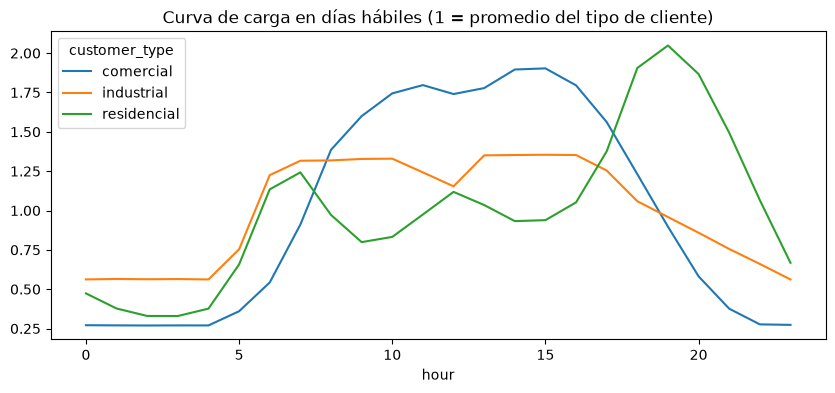

In [8]:
curva = sql('''
    SELECT m.customer_type, hour(r.ts) AS hour, avg(r.kwh) * 4 AS kwh_hour
    FROM readings r JOIN meters m USING (meter_id)
    WHERE dayofweek(r.ts) BETWEEN 2 AND 6
    GROUP BY m.customer_type, hour(r.ts)
''')
curva["normalizado"] = curva["kwh_hour"] / curva.groupby("customer_type")["kwh_hour"].transform("mean")
curva.pivot(index="hour", columns="customer_type", values="normalizado").plot(
    figsize=(10, 4), title="Curva de carga en días hábiles (1 = promedio del tipo de cliente)")
plt.show()

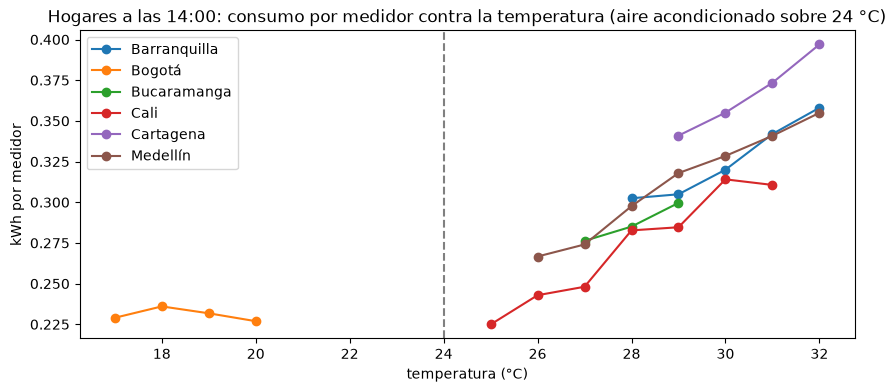

In [9]:
calor = sql('''
    SELECT m.city, round(w.temperature_c) AS temperature, avg(h.kwh) AS kwh_per_meter, count(*) AS hours
    FROM (SELECT meter_id, date_trunc('HOUR', ts) AS hour, sum(kwh) AS kwh FROM readings GROUP BY 1, 2) h
    JOIN meters m USING (meter_id)
    JOIN weather w ON w.city = m.city AND w.ts = h.hour
    WHERE m.customer_type = 'residencial' AND hour(h.hour) = 14
    GROUP BY m.city, round(w.temperature_c)
    HAVING count(*) >= 20
''')
fig, ax = plt.subplots(figsize=(10, 4))
for city, grupo in calor.groupby("city"):
    grupo.sort_values("temperature").plot(x="temperature", y="kwh_per_meter", ax=ax, label=city, marker="o")
ax.axvline(24, color="gray", linestyle="--")
ax.set(title="Hogares a las 14:00: consumo por medidor contra la temperatura (aire acondicionado sobre 24 °C)",
       xlabel="temperatura (°C)", ylabel="kWh por medidor")
plt.show()

### Juega aquí: un circuito, un día

Cambia el circuito y la fecha: `BAQ-03` el 17 tuvo un corte; `CLO-02` tiene subtensión todas las noches.

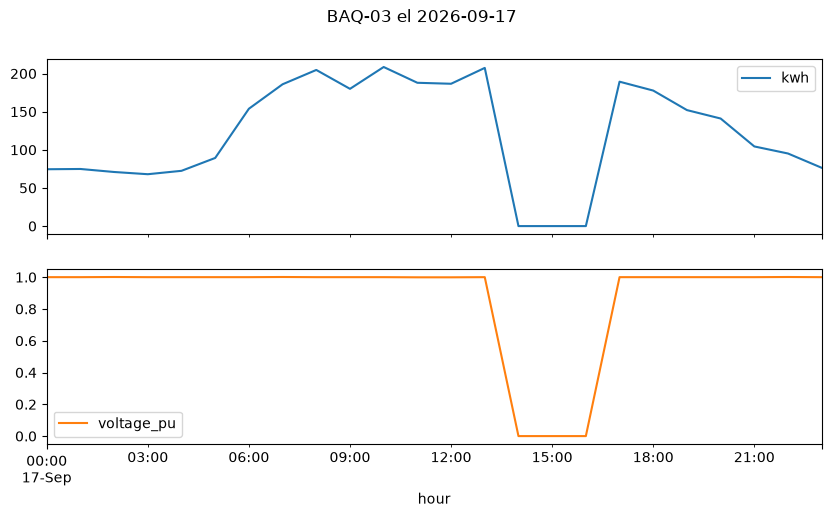

In [10]:
FEEDER, DAY = "BAQ-03", "2026-09-17"
dia = sql(f'''
    SELECT hour, kwh, voltage_pu, temperature_c FROM feeder_hourly
    WHERE feeder = '{FEEDER}' AND to_date(hour) = '{DAY}' ORDER BY hour
''')
dia.set_index("hour")[["kwh", "voltage_pu"]].plot(subplots=True, figsize=(10, 5), title=f"{FEEDER} el {DAY}")
plt.show()

## 5. Planes y rendimiento

`plan()` muestra qué va a hacer Spark: qué archivos lee (`PartitionFilters`), qué filtros empuja al lector
(`PushedFilters`), qué columnas lee (`ReadSchema`) y dónde hay shuffle (`Exchange`).

In [11]:
plan("SELECT sum(kwh) FROM readings WHERE date = '2026-09-15' AND meter_id = 'M00001'")

== Physical Plan ==
AdaptiveSparkPlan (7)
+- HashAggregate (6)
   +- Exchange (5)
      +- HashAggregate (4)
         +- Project (3)
            +- Filter (2)
               +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [meter_id#0, kwh#2, date#5]
Batched: true
Location: InMemoryFileIndex [hdfs://master:8020/datalake/silver/readings]
PartitionFilters: [isnotnull(date#5), (date#5 = 2026-09-15)]
PushedFilters: [IsNotNull(meter_id), EqualTo(meter_id,M00001)]
ReadSchema: struct<meter_id:string,kwh:double>

(2) Filter
Input [3]: [meter_id#0, kwh#2, date#5]
Condition : (isnotnull(meter_id#0) AND (meter_id#0 = M00001))

(3) Project
Output [1]: [kwh#2]
Input [3]: [meter_id#0, kwh#2, date#5]

(4) HashAggregate
Input [1]: [kwh#2]
Keys: []
Functions [1]: [partial_sum(kwh#2)]
Aggregate Attributes [1]: [sum#140]
Results [1]: [sum#141]

(5) Exchange
Input [1]: [sum#141]
Arguments: SinglePartition, ENSURE_REQUIREMENTS, [plan_id=822]

(6) HashAggregate
Input [1]: [sum#141]
Keys: []
Functions [1

### Juega aquí: joins y particiones de shuffle

Cambia el umbral de broadcast (`-1` lo desactiva) y las particiones de shuffle, y mira el plan y el tiempo.

In [12]:
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "10MB")  # prueba "-1"
spark.conf.set("spark.sql.shuffle.partitions", "8")  # prueba "200"
consulta = "SELECT m.feeder, sum(r.kwh) FROM readings r JOIN meters m USING (meter_id) GROUP BY m.feeder"
inicio = time.perf_counter()
spark.sql(consulta).collect()
print(f"{time.perf_counter() - inicio:.2f} s")
plan(consulta)

0.95 s
== Physical Plan ==
AdaptiveSparkPlan (12)
+- HashAggregate (11)
   +- Exchange (10)
      +- HashAggregate (9)
         +- Project (8)
            +- BroadcastHashJoin Inner BuildRight (7)
               :- Project (3)
               :  +- Filter (2)
               :     +- Scan parquet  (1)
               +- BroadcastExchange (6)
                  +- Filter (5)
                     +- Scan parquet  (4)


(1) Scan parquet 
Output [3]: [meter_id#0, kwh#2, date#5]
Batched: true
Location: InMemoryFileIndex [hdfs://master:8020/datalake/silver/readings]
PushedFilters: [IsNotNull(meter_id)]
ReadSchema: struct<meter_id:string,kwh:double>

(2) Filter
Input [3]: [meter_id#0, kwh#2, date#5]
Condition : isnotnull(meter_id#0)

(3) Project
Output [2]: [meter_id#0, kwh#2]
Input [3]: [meter_id#0, kwh#2, date#5]

(4) Scan parquet 
Output [2]: [meter_id#6, feeder#10]
Batched: true
Location: InMemoryFileIndex [hdfs://master:8020/datalake/silver/meters]
PushedFilters: [IsNotNull(meter_id)]
ReadSc

In [13]:
# Cuántas filas tiene cada partición (repartition reparte, coalesce junta sin mover datos)
particiones(spark.table("meters").repartition(4))

,partición,filas
0,0,250
1,1,250
2,2,250
3,3,250


## 6. Kafka

Un tema propio, `sandbox-events`, para producir y consumir lo que quieras sin afectar a las lecciones.

In [14]:
from confluent_kafka.admin import NewTopic

TOPIC = "sandbox-events"
kafka = admin()
if TOPIC not in kafka.list_topics(timeout=10).topics:
    kafka.create_topics([NewTopic(TOPIC, num_partitions=3, replication_factor=3)])[TOPIC].result()
topico(TOPIC)

,partition,leader,replicas,isr
0,0,2,"[2, 3, 1]","[2, 3, 1]"
1,1,3,"[3, 1, 2]","[3, 1, 2]"
2,2,1,"[1, 2, 3]","[1, 2, 3]"


### Juega aquí: producir y consumir

Cambia las claves, la cantidad de mensajes o el grupo. Con el mismo grupo, el segundo `leer()` sigue donde quedó el
primero; con un grupo nuevo, lee todo desde el principio.

In [15]:
escritor = producer(**{"acks": "all"})
for i in range(30):
    clave = f"medidor-{i % 5}"
    escritor.produce(TOPIC, key=clave, value=json.dumps({"i": i, "kwh": round(i * 0.1, 1)}))
escritor.flush()


def leer(grupo, maximo=10):
    lector = consumer(grupo)
    lector.subscribe([TOPIC])
    mensajes = lector.consume(num_messages=maximo, timeout=10)
    lector.close()
    return pd.DataFrame([{"partición": m.partition(), "offset": m.offset(), "clave": m.key().decode(),
                          "valor": m.value().decode()} for m in mensajes])


leer("sandbox-grupo")

,partición,offset,clave,valor
0,0,10,medidor-1,"{""i"": 26, ""kwh"": 2.6}"
1,0,11,medidor-3,"{""i"": 28, ""kwh"": 2.8}"
2,0,12,medidor-1,"{""i"": 1, ""kwh"": 0.1}"
3,0,13,medidor-3,"{""i"": 3, ""kwh"": 0.3}"
4,0,14,medidor-1,"{""i"": 6, ""kwh"": 0.6}"
5,0,15,medidor-3,"{""i"": 8, ""kwh"": 0.8}"
6,0,16,medidor-1,"{""i"": 11, ""kwh"": 1.1}"
7,0,17,medidor-3,"{""i"": 13, ""kwh"": 1.3}"
8,0,18,medidor-1,"{""i"": 16, ""kwh"": 1.6}"
9,0,19,medidor-3,"{""i"": 18, ""kwh"": 1.8}"


## 7. Streaming en vivo

El simulador reproduce un día en `meter-readings`; una consulta de streaming lo agrega por ciudad en ventanas de
15 minutos y escribe en una tabla en memoria (`memory` sink) que puedes consultar con SQL **mientras corre**.

In [16]:
lecturas = (spark.readStream.format("kafka")
            .option("kafka.bootstrap.servers", KAFKA_BOOTSTRAP_SERVERS)
            .option("subscribe", READINGS_TOPIC)
            .option("startingOffsets", "latest")
            .load()
            .select(F.from_json(F.col("value").cast("string"),
                                "meter_id string, ts string, kwh double, voltage double").alias("r"))
            .select("r.*")
            .withColumn("ts", F.to_timestamp("ts")))
ciudades = spark.table("meters").select("meter_id", "city")
en_vivo = (lecturas.join(F.broadcast(ciudades), "meter_id")
           .groupBy(F.window("ts", "15 minutes"), "city")
           .agg(F.round(F.sum("kwh"), 1).alias("kwh"), F.count("*").alias("readings"))
           .writeStream.format("memory").queryName("en_vivo").outputMode("complete")
           .trigger(processingTime="2 seconds").start())
replay = Replay(date(2026, 9, 29), start_slot=68, slots=16, seconds_per_slot=2.0)  # 17:00 a 21:00
replay.start()
time.sleep(10)
sql("SELECT window.start AS desde, city, kwh, readings FROM en_vivo ORDER BY desde DESC, kwh DESC", 12)

,desde,city,kwh,readings
0,2026-09-29 17:45:00,Bogotá,549.1,318
1,2026-09-29 17:45:00,Medellín,245.9,214
2,2026-09-29 17:45:00,Cartagena,228.4,96
3,2026-09-29 17:45:00,Cali,226.1,166
4,2026-09-29 17:45:00,Barranquilla,119.0,120
5,2026-09-29 17:45:00,Bucaramanga,104.2,86
6,2026-09-29 17:30:00,Bogotá,556.2,318
7,2026-09-29 17:30:00,Medellín,238.8,214
8,2026-09-29 17:30:00,Cartagena,235.9,96
9,2026-09-29 17:30:00,Cali,225.5,166


### Juega aquí: vuelve a consultar mientras corre

Ejecuta esta celda varias veces: aparecen ventanas nuevas. Cuando el simulador termine (32 s), detén la consulta.

intervalo actual del simulador: 75 | enviadas: 8000


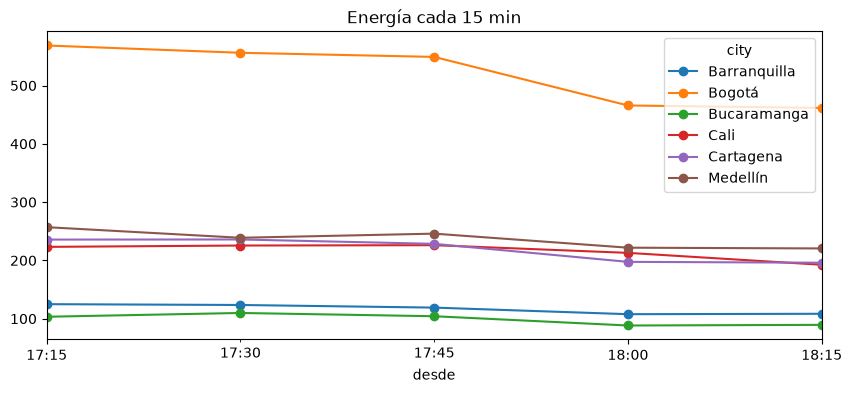

In [17]:
print("intervalo actual del simulador:", replay.current_slot, "| enviadas:", replay.sent)
tabla = sql("SELECT window.start AS desde, city, kwh FROM en_vivo")
tabla.pivot(index="desde", columns="city", values="kwh").plot(figsize=(10, 4), marker="o", title="Energía cada 15 min")
plt.show()

In [18]:
replay.stop()
en_vivo.processAllAvailable()  # terminar el micro-lote en curso antes de detener la consulta
en_vivo.stop()
en_vivo.lastProgress

{
    "id": "de61440b-7b77-4674-8609-000b309eee3f",
    "runId": "3fa53afd-0fd7-4740-ae7c-6b23059cce47",
    "name": "en_vivo",
    "timestamp": "2026-10-10T17:15:52.003Z",
    "batchId": 8,
    "batchDuration": 1089,
    "numInputRows": 1000,
    "inputRowsPerSecond": 500.0,
    "processedRowsPerSecond": 918.3,
    "durationMs": {
        "addBatch": 958,
        "commitOffsets": 19,
        "getBatch": 1,
        "latestOffset": 29,
        "queryPlanning": 60,
        "triggerExecution": 1088,
        "walCommit": 20
    },
    "stateOperators": [
        {
            "operatorName": "stateStoreSave",
            "numRowsTotal": 54,
            "numRowsUpdated": 6,
            "allUpdatesTimeMs": 88,
            "numRowsRemoved": 0,
            "allRemovalsTimeMs": 0,
            "commitTimeMs": 171,
            "memoryUsedBytes": 20032,
            "numRowsDroppedByWatermark": 0,
            "numShufflePartitions": 8,
            "numStateStoreInstances": 8,
            "customMet

## 8. MLlib

El modelo de la lección 08 (`/models/hourly_kwh`) predice el consumo de cada medidor y hora.

In [19]:
from pyspark.ml import PipelineModel

modelo = PipelineModel.load(f"{MODELS}/hourly_kwh")
base = (spark.table("readings").groupBy("meter_id", F.date_trunc("HOUR", "ts").alias("hour")).agg(F.sum("kwh").alias("kwh"))
        .join(spark.table("meters"), "meter_id")
        .join(spark.table("weather").withColumnRenamed("ts", "hour"), ["city", "hour"])
        .join(spark.read.parquet(f"{GOLD}/meter_profile"), "meter_id")
        .withColumn("hour_of_day", F.hour("hour"))
        .withColumn("day_of_week", F.dayofweek("hour"))
        .withColumn("is_weekend", F.col("day_of_week").isin(1, 7).cast("int"))
        .withColumn("stratum", F.coalesce("stratum", F.lit(0))))
print([type(s).__name__ for s in modelo.stages])

12:15:59 WARN FileStreamSink: Assume no metadata directory. Error while looking for metadata directory in the path: /models/hourly_kwh/metadata.
java.io.FileNotFoundException: File does not exist: /models/hourly_kwh/metadata
	at org.apache.hadoop.hdfs.DistributedFileSystem$29.doCall(DistributedFileSystem.java:1842)
	at org.apache.hadoop.hdfs.DistributedFileSystem$29.doCall(DistributedFileSystem.java:1835)
	at org.apache.hadoop.fs.FileSystemLinkResolver.resolve(FileSystemLinkResolver.java:81)
	at org.apache.hadoop.hdfs.DistributedFileSystem.getFileStatus(DistributedFileSystem.java:1850)
	at org.apache.spark.sql.execution.streaming.sinks.FileStreamSink$.hasMetadata(FileStreamSink.scala:58)
	at org.apache.spark.sql.execution.datasources.DataSource.resolveRelation(DataSource.scala:394)
	at org.apache.spark.sql.catalyst.analysis.ResolveDataSource.org$apache$spark$sql$catalyst$analysis$ResolveDataSource$$loadV1BatchSource(ResolveDataSource.scala:210)
	at org.apache.spark.sql.catalyst.analysi

AnalysisException: [PATH_NOT_FOUND] Path does not exist: hdfs://master:8020/models/hourly_kwh/metadata. SQLSTATE: 42K03

### Juega aquí: real contra predicho

Cambia el medidor (los de Barranquilla y Cartagena dependen más de la temperatura) o el rango de fechas. Prueba un
medidor con fraude simulado: `sorted(dataset.FRAUD)[:5]`.

In [20]:
METER = "M00005"
serie = (modelo.transform(base.where(f"meter_id = '{METER}' AND hour >= '2026-09-24'"))
         .select("hour", "kwh", "prediction").orderBy("hour").toPandas())
serie.set_index("hour").plot(figsize=(12, 4), title=f"{METER}: consumo real y predicho (semana de prueba)")
plt.show()

NameError: name 'modelo' is not defined

----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 56824)
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/socketserver.py", line 318, in _handle_request_noblock
    self.process_request(request, client_address)
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/socketserver.py", line 349, in process_request
    self.finish_request(request, client_address)
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/socketserver.py", line 362, in finish_request
    self.RequestHandlerClass(request, client_address, self)
    ~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/socketserver.py", line 766, in __init__
    self.handle()
    ~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/site-packages/pyspark/accumulators.py", line 329, in handle
    poll(accum_updates)
    ~~~~^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3

### Juega aquí: ¿qué pasa si hace más calor?

El mismo día con la temperatura desplazada: el modelo responde con el aire acondicionado que aprendió.

In [21]:
DELTA = 4.0  # grados extra
dia = base.where(f"meter_id = '{METER}' AND to_date(hour) = '2026-09-28'")
escenarios = {
    "real": modelo.transform(dia),
    f"+{DELTA} °C": modelo.transform(dia.withColumn("temperature_c", F.col("temperature_c") + DELTA)),
}
comparacion = pd.DataFrame({nombre: d.orderBy("hour").select("prediction").toPandas()["prediction"]
                            for nombre, d in escenarios.items()})
comparacion.plot(figsize=(10, 4), title=f"{METER}: consumo predicho por hora del 28 de septiembre")
plt.show()

NameError: name 'base' is not defined

## 9. Tu propio experimento

Escribe en `/sandbox` lo que quieras: un DataFrame tuyo, un agregado, otro formato. Luego léelo con SQL.

In [22]:
mio = spark.createDataFrame(
    [("M00001", "2026-10-01", 3.2), ("M00002", "2026-10-01", 4.8), ("M00001", "2026-10-02", 2.9)],
    "meter_id string, date string, kwh double")
mio.write.mode("overwrite").partitionBy("date").parquet("/sandbox/mis_lecturas")
hdfs("dfs", "-ls", "-R", "/sandbox/mis_lecturas")
spark.read.parquet("/sandbox/mis_lecturas").createOrReplaceTempView("mis_lecturas")
sql("SELECT * FROM mis_lecturas ORDER BY date")

ConnectionRefusedError: [Errno 111] Connection refused

In [23]:
# Liberar el clúster: detiene la SparkSession (y sus ejecutores en YARN)
spark.stop()

ConnectionRefusedError: [Errno 111] Connection refused